# Tahap 3: EDA Pasca-*Preprocessing* & Analisis Daya Pisah Fitur (*Cohen's $d$*)

Setelah data dibersihkan dan dinormalisasi terhadap patokan personal (*personal baseline*) serta dikompensasi dengan sensor SHT31 pada **Tahap 2**, kita melakukan **EDA Kedua (Pasca-*Preprocessing*)** untuk membuktikan peningkatan kualitas sinyal sebelum masuk ke pelatihan model.

### Analisis yang Dilakukan:
1. **Perbandingan *Effect Size* (*Cohen's $d$*) Sebelum vs. Sesudah *Preprocessing***:
   $$d = \frac{|\mu_{\text{hipo}} - \mu_{\text{normal}}|}{s_{\text{pooled}}}$$
2. **Pemetaan Ruang Fitur 2 Dimensi (*2D Feature Space*)**:
   - **Ruang Fitur Jalur 1 ($\Delta\text{HR}$ vs $\text{PRV}_{\text{rel}}$)**: Menunjukkan mengapa pemisah linear (**Logistic Regression**) cocok untuk menyaring kandidat anomali otonom.
   - **Ruang Fitur Gabungan ($\Delta\text{HR}$ vs $\text{VOC}_{\text{rel}}$)**: Menunjukkan bagaimana **Jalur 2 (VOC + SHT31)** memisahkan dengan tegas pasien Hipoglikemia sejati dari subjek Normal yang mengalami kenaikan HR non-hipoglikemik.

Kelompok Sinyal      | Fitur Mentah             d Awal | Fitur Pasca-Preprocess                       d Baru | Kenaikan
----------------------------------------------------------------------------------------------------------------------
1. Detak Jantung     | hr                        1.28x | Simpangan HR Personal (hr_delta)              1.61x | + 26.4%
2. Variabilitas PRV  | prv                       0.88x | Simpangan PRV Personal (prv_rel)              1.69x | + 92.0%
3. Gas Aseton VOC    | voc                       0.55x | Simpangan VOC + SHT31 (voc_rel_comp)          1.39x | +151.8%


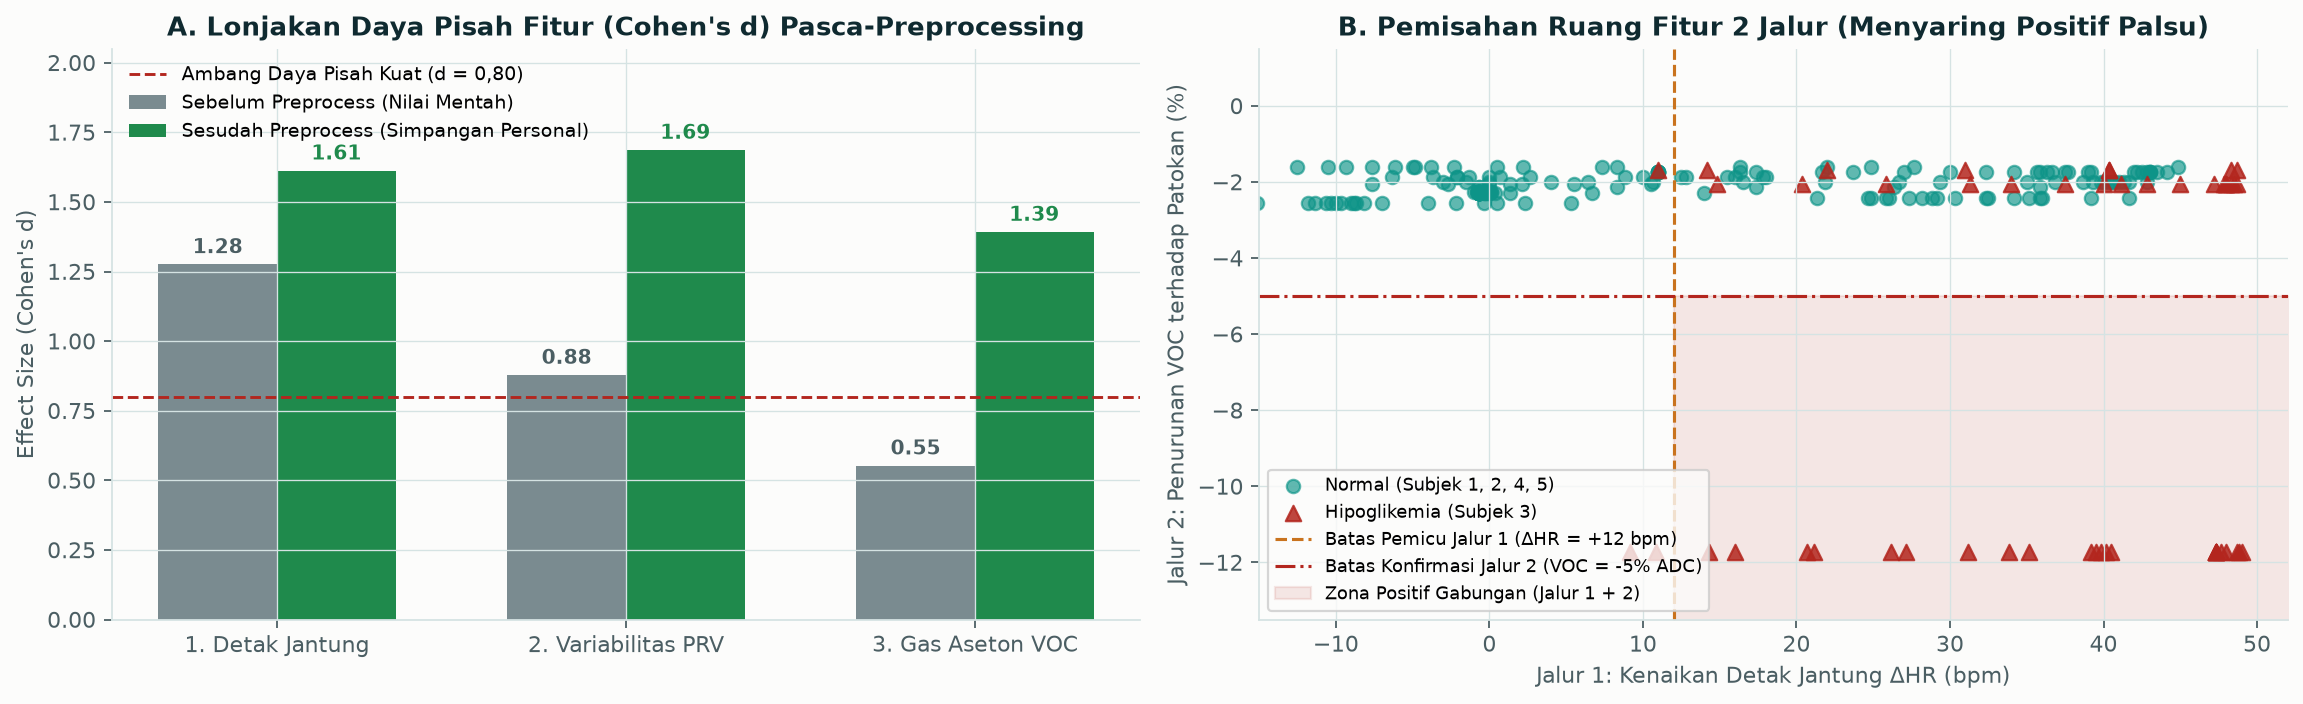

In [1]:
def cohens_d(x1, x0):
    s1, s0 = np.std(x1, ddof=1), np.std(x0, ddof=1)
    sp = np.sqrt((s1**2 + s0**2) / 2.0)
    return abs(np.mean(x1) - np.mean(x0)) / sp if sp > 0 else 0.0

pasangan_fitur = [
    ("HR Mentah (bpm)", "hr", "Simpangan HR Personal (ΔHR)", "hr_delta"),
    ("PRV Mentah (ms)", "prv", "Simpangan PRV Personal (PRV_rel)", "prv_rel"),
    ("VOC Mentah (ADC)", "voc", "Simpangan VOC Terkompensasi (VOC_rel_comp)", "voc_rel_comp"),
]

print(f"{'Kelompok Sinyal':<20} | {'Fitur Mentah':<22} {'d Awal':>8} | {'Fitur Pasca-Preprocess':<42} {'d Baru':>8} | {'Kenaikan'}")
print("-" * 118)
d_before, d_after, labels_grp = [], [], []
for grp, c_raw, l_new, c_new in [
    ("1. Detak Jantung", "hr", "Simpangan HR Personal (hr_delta)", "hr_delta"),
    ("2. Variabilitas PRV", "prv", "Simpangan PRV Personal (prv_rel)", "prv_rel"),
    ("3. Gas Aseton VOC", "voc", "Simpangan VOC + SHT31 (voc_rel_comp)", "voc_rel_comp"),
]:
    d0 = cohens_d(df_clean[df_clean["label"]==1][c_raw], df_clean[df_clean["label"]==0][c_raw])
    d1 = cohens_d(df_clean[df_clean["label"]==1][c_new], df_clean[df_clean["label"]==0][c_new])
    d_before.append(d0); d_after.append(d1); labels_grp.append(grp)
    pct_up = ((d1 - d0) / d0) * 100.0
    print(f"{grp:<20} | {c_raw:<22} {d0:7.2f}x | {l_new:<42} {d1:7.2f}x | +{pct_up:5.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.5))

# Grafik A: Peningkatan Cohen's d Sebelum vs Sesudah Preprocessing
x = np.arange(len(labels_grp))
w = 0.34
axes[0].bar(x - w/2, d_before, width=w, color=ABU, label="Sebelum Preprocess (Nilai Mentah)")
axes[0].bar(x + w/2, d_after, width=w, color=HIJAU, label="Sesudah Preprocess (Simpangan Personal)")
axes[0].axhline(0.80, color=MERAH, ls="--", lw=1.3, label="Ambang Daya Pisah Kuat (d = 0,80)")
for i in range(len(x)):
    axes[0].text(x[i] - w/2, d_before[i] + 0.04, f"{d_before[i]:.2f}", ha="center", fontsize=8.8, color=TINTA2, fontweight="bold")
    axes[0].text(x[i] + w/2, d_after[i] + 0.04, f"{d_after[i]:.2f}", ha="center", fontsize=9.2, color=HIJAU, fontweight="bold")
axes[0].set_xticks(x, labels_grp)
axes[0].set_ylim(0, 2.05)
axes[0].set_ylabel("Effect Size (Cohen's d)")
axes[0].set_title("A. Lonjakan Daya Pisah Fitur (Cohen's d) Pasca-Preprocessing", fontweight="bold", color=TINTA)
axes[0].legend(frameon=False, fontsize=8.5, loc="upper left")

# Grafik B: Scatter Plot 2D (Jalur 1 ΔHR vs Jalur 2 VOC_rel)
norm_pts = df_clean[df_clean["label"] == 0]
hypo_pts = df_clean[df_clean["label"] == 1]
axes[1].scatter(norm_pts["hr_delta"], norm_pts["voc_rel"] * 100, c=BIRU, alpha=0.65, s=36, label="Normal (Subjek 1, 2, 4, 5)")
axes[1].scatter(hypo_pts["hr_delta"], hypo_pts["voc_rel"] * 100, c=MERAH, alpha=0.85, s=48, marker="^", label="Hipoglikemia (Subjek 3)")
axes[1].axvline(12.0, color=JINGGA, ls="--", lw=1.4, label="Batas Pemicu Jalur 1 (ΔHR = +12 bpm)")
axes[1].axhline(-5.0, color=MERAH, ls="-.", lw=1.4, label="Batas Konfirmasi Jalur 2 (VOC = -5% ADC)")
axes[1].fill_between([12, 55], -14, -5.0, color=MERAH, alpha=0.10, label="Zona Positif Gabungan (Jalur 1 + 2)")
axes[1].set_xlim(-15, 52); axes[1].set_ylim(-13.5, 1.5)
axes[1].set_xlabel("Jalur 1: Kenaikan Detak Jantung ΔHR (bpm)")
axes[1].set_ylabel("Jalur 2: Penurunan VOC terhadap Patokan (%)")
axes[1].set_title("B. Pemisahan Ruang Fitur 2 Jalur (Menyaring Positif Palsu)", fontweight="bold", color=TINTA)
axes[1].legend(frameon=True, facecolor="#fcfcfb", fontsize=8.0, loc="lower left")

for a in axes:
    a.grid(color=GARIS, lw=0.6)
    a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()